# 03 — Forecasting Protocol and Preprocessing

Stage 04. Fixes the forecasting task, temporal splits, backtesting scheme, missing-value policy and feature availability **before** any model is fitted. The definitions live in `src/protocol.py` so every later stage uses the same ones.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.data import load_raw, validate
from src import protocol as P
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
pm = df['pm25']

## 1. Forecasting task
| Item | Definition |
|---|---|
| Target | PM2.5 concentration (µg/m³, US Embassy) at hour *t + 1* |
| Horizon | 1 hour |
| Issuance time *t* | End of hour *t*, when all hour-*t* observations are available |
| Allowed inputs | Observations at hours ≤ *t* (PM2.5 and airport weather), plus calendar attributes of *t + 1*, which are known in advance |
| Not allowed | Any value from hours > *t*, including realised future weather |
| Metrics | MAE, RMSE (µg/m³) and R² on the original scale |

**Assumption:** each hourly value is available at the end of its hour (no reporting delay). The dataset does not document latency, so this is stated as an assumption.

In [2]:
y = P.make_target(pm)
check = pd.DataFrame({'pm25 (t)': pm, 'target y(t)': y}).iloc[24:28]
assert (y.iloc[:-1].values[~np.isnan(y.iloc[:-1].values)] == pm.iloc[1:].dropna().values).all()
check

,pm25 (t),target y(t)
timestamp,,
2010-01-02 00:00:00,129.0,148.0
2010-01-02 01:00:00,148.0,159.0
2010-01-02 02:00:00,159.0,181.0
2010-01-02 03:00:00,181.0,138.0


## 2. Chronological splits
Splits use whole calendar years so each one contains every season (seasonality was strong in the tail, Stage 03). A sample is assigned by its **target** hour, so the sample issued at 2012-12-31 23:00 (target 2013-01-01 00:00) belongs to validation, not training.

In [3]:
split = P.assign_split(df.index)
mask = P.eval_mask(pm)
summary = pd.DataFrame({
    'target from': [P.SPLITS[s][0] for s in P.SPLITS], 'target to': [P.SPLITS[s][1] for s in P.SPLITS],
    'samples': [int((split == s).sum()) for s in P.SPLITS],
    'target observed': [int(((split == s) & y.notna()).sum()) for s in P.SPLITS],
    'common eval set': [int(((split == s) & mask).sum()) for s in P.SPLITS],
}, index=list(P.SPLITS))
summary['% of samples scored'] = (100 * summary['common eval set'] / summary['samples']).round(1)
summary

,target from,target to,samples,target observed,common eval set,% of samples scored
train,2010-01-01,2012-12-31 23:00,26303,24418,23452,89.2
val,2013-01-01,2013-12-31 23:00,8760,8678,8563,97.8
test,2014-01-01,2014-12-31 23:00,8760,8661,8531,97.4


In [4]:
print('unassigned issuance times:', list(df.index[split.isna()]))
print(split.loc['2012-12-31 22:00':'2013-01-01 00:00'])

unassigned issuance times: [Timestamp('2014-12-31 23:00:00')]
timestamp
2012-12-31 22:00:00    train
2012-12-31 23:00:00      val
2013-01-01 00:00:00      val
Name: split, dtype: object


## 3. Backtesting protocol
- **Tuning (Stage 07):** expanding-window over the validation year with 4 quarterly folds. Each fold trains on all targets before the quarter and scores the quarter. Hyperparameters are chosen on the mean across folds. The test year is never used.
- **Final evaluation (Stage 08):** expanding-window over the test year with 12 monthly folds. Before each month the model is refit on all earlier data with the **fixed** Stage 07 hyperparameters, as an operational forecaster would be. A single fixed-origin fit (train 2010–2013 → test 2014) is reported as a secondary result.
- **Baselines** have no fitted parameters, so they are scored on the same timestamps without refitting.
- Metrics are pooled over all scored hours of a period; per-fold values are also reported to show variability.

In [5]:
tune = pd.DataFrame(P.backtest_folds('2013-01-01', '2013-12-31 23:00', freq='QS'))
test = pd.DataFrame(P.backtest_folds('2014-01-01', '2014-12-31 23:00', freq='MS'))
def n_scored(f):
    tr, te = P.fold_masks(df.index, f)
    return pd.Series({'train samples (target observed)': int((tr & y.notna()).sum()), 'test samples (eval set)': int((te & mask).sum())})
tune = tune.join(tune.apply(n_scored, axis=1)); test = test.join(test.apply(n_scored, axis=1))
display(tune); display(test)

,fold,train_end,test_start,test_end,train samples (target observed),test samples (eval set)
0,1,2012-12-31 23:00:00,2013-01-01,2013-03-31 23:00:00,24418,2127
1,2,2013-03-31 23:00:00,2013-04-01,2013-06-30 23:00:00,26567,2129
2,3,2013-06-30 23:00:00,2013-07-01,2013-09-30 23:00:00,28727,2161
3,4,2013-09-30 23:00:00,2013-10-01,2013-12-31 23:00:00,30916,2146


,fold,train_end,test_start,test_end,train samples (target observed),test samples (eval set)
0,1,2013-12-31 23:00:00,2014-01-01,2014-01-31 23:00:00,33096,728
1,2,2014-01-31 23:00:00,2014-02-01,2014-02-28 23:00:00,33833,663
2,3,2014-02-28 23:00:00,2014-03-01,2014-03-31 23:00:00,34502,741
3,4,2014-03-31 23:00:00,2014-04-01,2014-04-30 23:00:00,35245,712
4,5,2014-04-30 23:00:00,2014-05-01,2014-05-31 23:00:00,35962,739
5,6,2014-05-31 23:00:00,2014-06-01,2014-06-30 23:00:00,36704,682
6,7,2014-06-30 23:00:00,2014-07-01,2014-07-31 23:00:00,37407,728
7,8,2014-07-31 23:00:00,2014-08-01,2014-08-31 23:00:00,38144,720
8,9,2014-08-31 23:00:00,2014-09-01,2014-09-30 23:00:00,38877,705
9,10,2014-09-30 23:00:00,2014-10-01,2014-10-31 23:00:00,39592,741


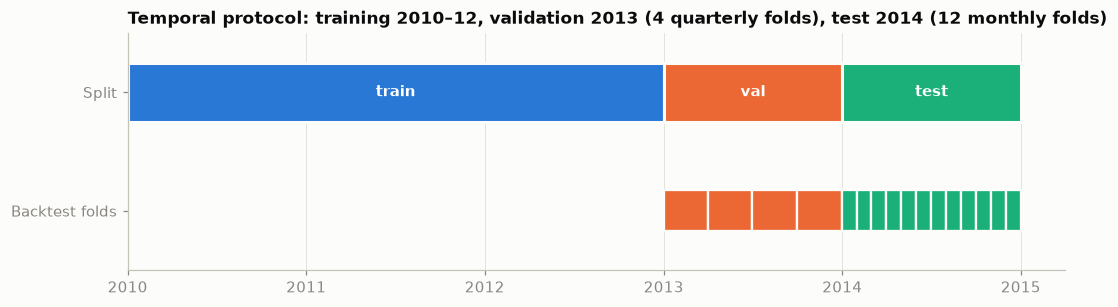

In [6]:
fig, ax = plt.subplots(figsize=(11, 2.8))
for i, (name, (s, e)) in enumerate(P.SPLITS.items()):
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    ax.barh(1, e - s, left=s, height=0.5, color=ps.SERIES[i], edgecolor=ps.SURFACE, linewidth=2)
    ax.text(s + (e - s) / 2, 1, name, ha='center', va='center', color='white', fontweight='bold')
for f, c in [(tune, ps.SERIES[1]), (test, ps.SERIES[2])]:
    for _, r in f.iterrows():
        ax.barh(0, r.test_end - r.test_start, left=r.test_start, height=0.35, color=c, edgecolor=ps.SURFACE, linewidth=1.5)
ax.set_yticks([1, 0], ['Split', 'Backtest folds'])
ax.set_title('Temporal protocol: training 2010–12, validation 2013 (4 quarterly folds), test 2014 (12 monthly folds)')
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(axis='y', visible=False); ax.set_ylim(-0.5, 1.5)
ps.save(fig, 'protocol_01_timeline'); plt.show()

## 4. Missing values and irregular timestamps
**Irregular timestamps:** none. The index is a complete hourly range, enforced by `validate()` on every load (Stage 02). No resampling is needed.

**Missing PM2.5 policy:**
| Where | Decision | Reason |
|---|---|---|
| Target *y(t)* missing | Drop the sample from training and scoring; never impute | An imputed target would train and score on invented values |
| PM2.5 inputs (lags, rolling stats) | Leave NaN; XGBoost handles missing values natively; rolling windows use a minimum-count rule (Stage 05) | Interpolation would use values after *t* (leakage); long forward-fills would invent flat episodes across gaps of up to 155 h |
| Scoring | All models are scored on the **common eval set**: target, *pm(t)* and *pm(t−23)* observed | Persistence and seasonal-naive are undefined otherwise; this keeps timestamps identical across models |
| Weather inputs | No missing values (Stage 02) | — |
| Fitted preprocessing | None is needed for tree models. If any is added later (e.g. scaling), it is fitted on training folds only | Prevents information from the evaluation period leaking into training |

Secondary check (Stage 08): XGBoost is also scored on all hours with an observed target, to show what the common-set restriction excludes.

In [7]:
lost = pd.DataFrame({s: {'target missing': int(((split == s) & y.isna()).sum()),
                         'pm(t) missing, target observed': int(((split == s) & y.notna() & pm.isna()).sum()),
                         'pm(t-23) missing only': int(((split == s) & y.notna() & pm.notna() & ~mask).sum())}
                     for s in P.SPLITS})
lost

,train,val,test
target missing,1885,82,99
"pm(t) missing, target observed",144,35,35
pm(t-23) missing only,822,80,95


## 5. Feature availability and leakage risks
| Feature group | Value used for issuance time *t* | Available at *t*? |
|---|---|---|
| PM2.5 lags | pm(t), pm(t−1), … | Yes |
| PM2.5 rolling mean / std | windows ending at *t* (inclusive) | Yes; must not be centred |
| Weather (dewp, temp, pres) | values at ≤ *t* | Yes |
| Wind direction, wind_cum, snow_cum, rain_cum | values at ≤ *t*; decoding uses only past rows | Yes |
| Calendar (hour, month, day of week) | of the target hour *t + 1* | Yes; deterministic |
| Weather at *t + 1* | realised future value | **No.** Excluded; would be an oracle analysis, not planned |

**Leakage risks and safeguards:**
1. *Centred or forward-looking windows* (e.g. `rolling(center=True)`, `shift(-k)` on inputs): all inputs are built with `shift(k ≥ 0)` and trailing windows; tested in Stage 05.
2. *Interpolating across gaps*: forbidden for inputs (uses future values).
3. *Boundary labels*: samples are assigned by target time, which stops the last training label from falling inside validation.
4. *Tuning on test*: hyperparameters are chosen on the 2013 folds only; 2014 is used once with fixed settings.
5. *EDA on the full period* (Stage 03): used only for qualitative choices such as the seasonal period and candidate lags.
6. *Fitting on all data*: any fitted transform is fitted inside each training fold.

## 6. Protocol checks

In [8]:
# 1. target alignment
assert (y.dropna().index + pd.Timedelta(hours=1)).isin(pm.dropna().index).all()
# 2. splits are disjoint, ordered and cover every issuance time except the final hour
tt = pd.Series(P.target_time(df.index), index=df.index)
assert split.isna().sum() == 1 and split.isna().iloc[-1]
assert tt[split == 'train'].max() < tt[split == 'val'].min() <= tt[split == 'val'].max() < tt[split == 'test'].min()
# 3. every backtest fold trains strictly before it tests, and test windows tile the period without overlap
for folds in (tune, test):
    for _, f in folds.iterrows():
        tr, te = P.fold_masks(df.index, f)
        assert tt[tr].max() < tt[te].min() and not (tr & te).any()
    assert (folds.test_start.iloc[1:].values == (folds.test_end.iloc[:-1] + pd.Timedelta(hours=1)).values).all()
# 4. tuning folds never touch the test year
assert tune.test_end.max() < pd.Timestamp(P.SPLITS['test'][0])
# 5. eval mask implies the target and both baseline inputs exist
assert y[mask].notna().all() and pm[mask].notna().all() and pm.shift(P.SEASONAL_PERIOD - P.HORIZON)[mask].notna().all()
print('all protocol checks passed')

all protocol checks passed
